#### MPAS time series plotting 
 Subsetting an Unstructured Grid: Analysis Over Hawaii
- Bounding Box: bugging
- Bounding Circle
- Nearest Neighbor
- Retrieving Orignal Grid Indices
  
Ming Ge Feb 2025

Reference:
- https://uxarray.readthedocs.io/en/latest/user-guide/subset.html
- https://uxarray.readthedocs.io/en/v2024.01.1/examples/009-subsetting.html 
- https://uxarray.readthedocs.io/en/latest/user-guide/data-structures.html
- https://projectpythia.org/unstructured-grid-viz-cookbook/notebooks/02-intro-to-uxarray/selection.html
- https://projectpythia.org/unstructured-grid-viz-cookbook/notebooks/04-recipes/mpas-atmo.html

In [1]:
%matplotlib inline
import uxarray as ux
import geoviews.feature as gf
import cartopy.crs as ccrs
import holoviews as hv
import warnings

plot_opts = {"width" : 600, "height": 300}

warnings.filterwarnings("ignore")

#### MPAS visulization
https://projectpythia.org/unstructured-grid-viz-cookbook/notebooks/04-recipes/mpas-atmo.html

In [2]:
dir_ghg = '/glade/campaign/mmm/c3we/mingge/MPAS-PGW/OLD/1993_PGW/'
dir_pgw = '/glade/campaign/mmm/c3we/mingge/MPAS-PGW/OLD/1993_PGW/'

flnm_grid = '/glade/campaign/mmm/c3we/mingge/MPAS-PGW/25-90km_PGW_tmp/x4.163842.grid_hawaii.nc'
flnm_data = dir_pgw + 'diag.1993-12-01_00.00.00.nc'

# Open dataset and grab a data variable of interest
uxds = ux.open_dataset(flnm_grid, flnm_data, use_dual = False)
uxda = uxds["relhum_200hPa"][0]


In [3]:
clim = (uxds['relhum_200hPa'][0].values.min(), uxds['relhum_200hPa'][0].values.max())
features = gf.coastline(projection=ccrs.PlateCarree(), line_width=1, scale='50m') * \
           gf.states(projection=ccrs.PlateCarree(), line_width=1, scale='50m')

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W

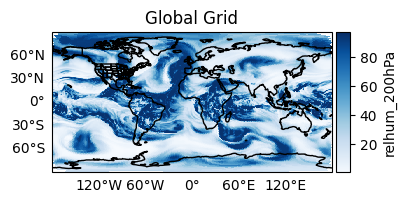

In [4]:
obj = uxds['relhum_200hPa'][0].plot.rasterize(method='polygon',
                                        exclude_antimeridian=True,
                                        title = "Global Grid",
                                        backend='matplotlib',
                                        **plot_opts) * features
hv.render(obj, backend='matplotlib')

#### analysis operations.

In [5]:
uxds['relhum_200hPa'][0].values.mean()

np.float32(39.945675)

#### Regional Subsets

In [6]:
uxds['relhum_200hPa'][0].subset

<uxarray.UxDataArray.subset>
Supported Methods:
  * nearest_neighbor(center_coord, k, element, inverse_indices, **kwargs)
  * bounding_circle(center_coord, r, element, inverse_indices, **kwargs)
  * bounding_box(lon_bounds, lat_bounds, inverse_indices, **kwargs)

In [7]:
uxds['relhum_200hPa'].uxgrid.subset

<uxarray.Grid.subset>
Supported Methods:
  * nearest_neighbor(center_coord, k, element, inverse_indices, **kwargs)
  * bounding_circle(center_coord, r, element, inverse_indices, **kwargs)
  * bounding_box(lon_bounds, lat_bounds, inverse_indices)

#### Bounding Box

In [8]:
#subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5))

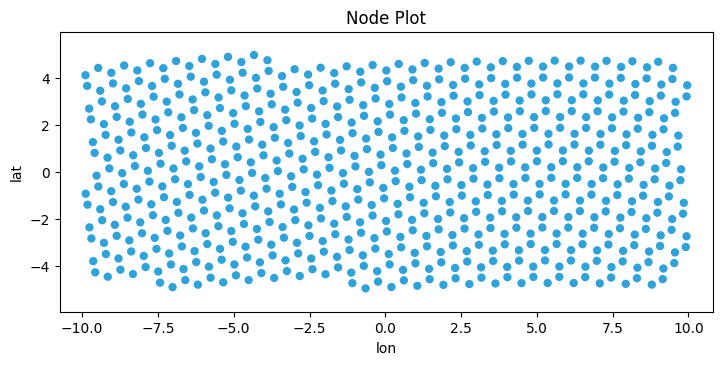

In [9]:
uxgrid = uxds.uxgrid
obj = uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot.nodes(title="Node Plot", backend='matplotlib')
hv.render(obj, backend='matplotlib')

In [10]:
uxgrid.subset

<uxarray.Grid.subset>
Supported Methods:
  * nearest_neighbor(center_coord, k, element, inverse_indices, **kwargs)
  * bounding_circle(center_coord, r, element, inverse_indices, **kwargs)
  * bounding_box(lon_bounds, lat_bounds, inverse_indices)

In [11]:
uxds['relhum_200hPa'][0].subset

<uxarray.UxDataArray.subset>
Supported Methods:
  * nearest_neighbor(center_coord, k, element, inverse_indices, **kwargs)
  * bounding_circle(center_coord, r, element, inverse_indices, **kwargs)
  * bounding_box(lon_bounds, lat_bounds, inverse_indices, **kwargs)

#### Bounding Box
Previously failed on an older uxarray version; works as of uxarray 2025.4.0

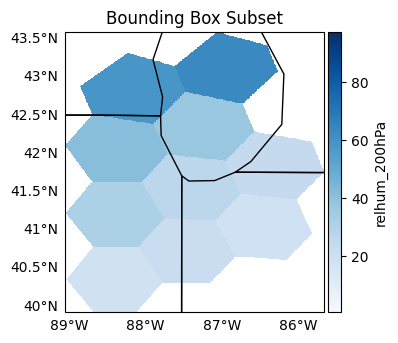

In [12]:
# https://uxarray.readthedocs.io/en/latest/user-guide/subset.html
lon_bounds = (-180 - 2, -120 + 2)
lat_bounds = (0 - 2, 40 + 2)
lon_bounds = (-87.6298 - 2, -87.6298 + 2)
lat_bounds = (41.8781 - 2, 41.8781 + 2)
inverse_indices=(["face", "node", "edge"], True)

bbox_subset_nodes = uxds['relhum_200hPa'][0].subset.bounding_box(lon_bounds, lat_bounds, inverse_indices=(["face", "node", "edge"], True))

obj = bbox_subset_nodes.plot.rasterize(method='polygon',
                                 exclude_antimeridian=True,
                                 clim=clim,
                                 title="Bounding Box Subset",
                                 backend='matplotlib',
                                 **plot_opts) * features
hv.render(obj, backend='matplotlib')

#### Bounding Circle
Using a center coordinate (lon, lat) and a radius (in degrees). The resulting subset will contain all elements within the radius of that circle.

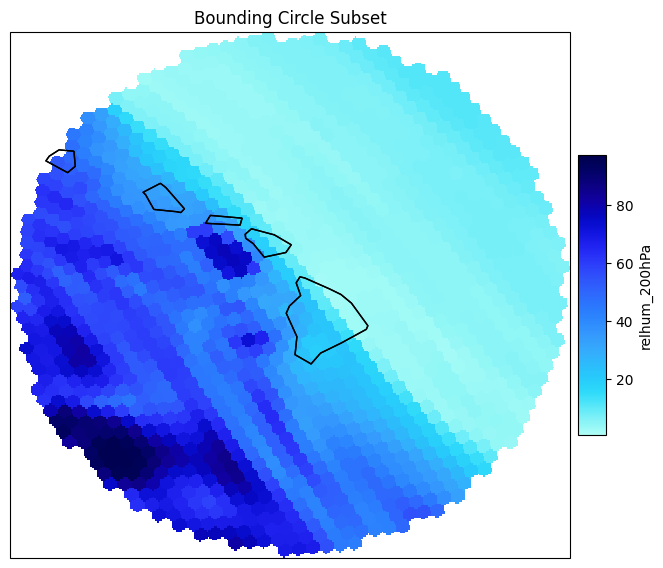

In [13]:
center_coord = [-156, 20]

r = 4
bcircle_subset = uxds["relhum_200hPa"][0].subset.bounding_circle(center_coord, r)

obj = bcircle_subset.plot(
    rasterize=True,
    periodic_elements="exclude",
    clim=clim,
    title="Bounding Circle Subset",
    backend='matplotlib',
    **plot_opts,
) * features
hv.render(obj, backend='matplotlib')

#### Nearest Neighbor
perform a nearest neighbor subset at some center coordinate (lon, lat) and query for some number of elements k

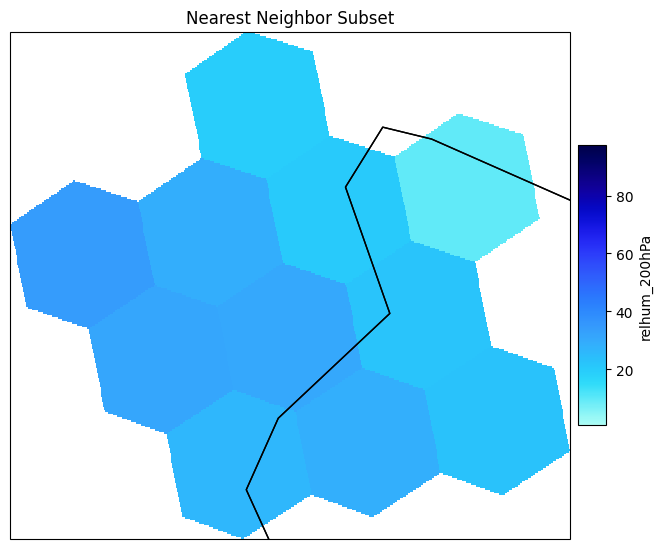

In [14]:
center_coord = [-156, 20]
nn_subset = uxds["relhum_200hPa"][0].subset.nearest_neighbor(
    center_coord, k=10, element="nodes"  # query against mesh nodes (corners), not cell/face centers
)

obj = nn_subset.plot(
    rasterize=True,
    periodic_elements="exclude",
    clim=clim,
    title="Nearest Neighbor Subset",
    backend='matplotlib',
    **plot_opts,
) * features
hv.render(obj, backend='matplotlib')

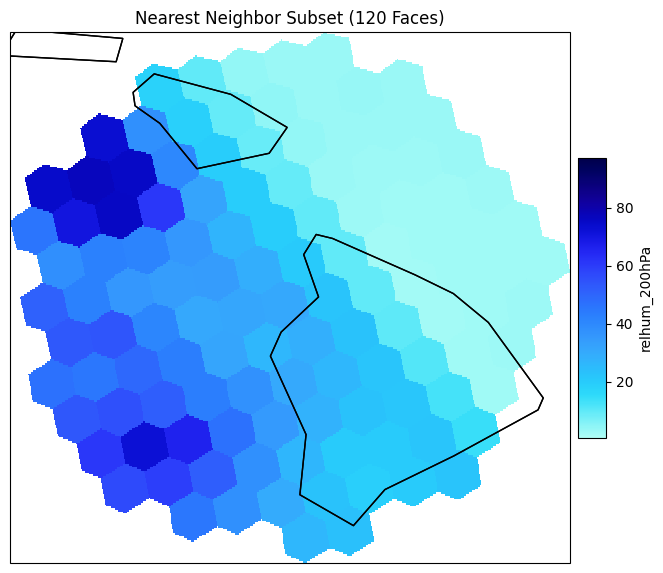

In [15]:
nn_subset_120 = uxds["relhum_200hPa"][0].subset.nearest_neighbor(
    center_coord, k=120, element="face centers"  # query against cell/face centers instead of nodes
)

obj = nn_subset_120.plot(
    rasterize=True,
    periodic_elements="exclude",
    clim=clim,
    title="Nearest Neighbor Subset (120 Faces)",
    backend='matplotlib',
    **plot_opts,
) * features
hv.render(obj, backend='matplotlib')

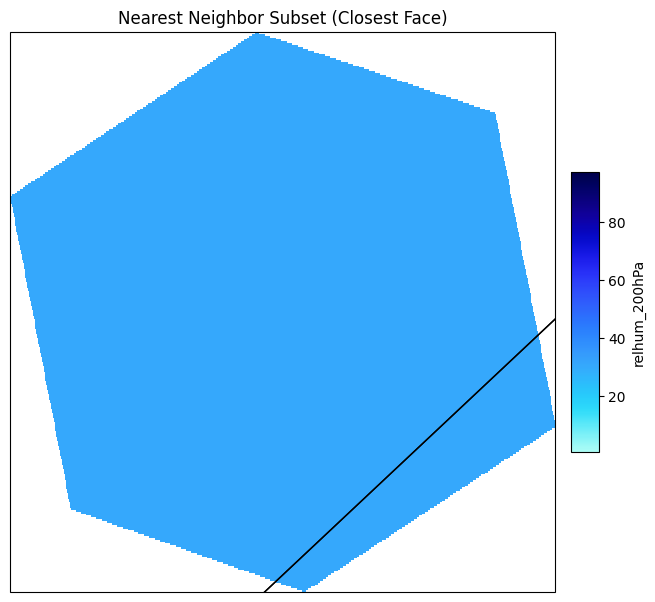

In [16]:
# When we set k=1, it selects the closest neighbor.

nn_subset_1 = uxds["relhum_200hPa"][0].subset.nearest_neighbor(
    center_coord, k=1, element="face centers"
)

obj = nn_subset_1.plot(
    rasterize=True,
    periodic_elements="exclude",
    clim=clim,
    title="Nearest Neighbor Subset (Closest Face)",
    backend='matplotlib',
    **plot_opts,
) * features
hv.render(obj, backend='matplotlib')

#### Analysis Operators on Regional Subsets

In [17]:
print("Global Mean:            ", uxds["relhum_200hPa"][0].values.mean())
#print("Bounding Box Mean:      ", bbox_subset_nodes.values.mean())
print("Bounding Circle Mean:   ", bcircle_subset.values.mean())

Global Mean:             39.945675
Bounding Circle Mean:    31.681105


#### Retrieving Orignal Grid Indices
 These indices can be stored within the subset with the inverse_indices variable. 
- Passing in True, which will store the face center indices

- Passing in a list of which indices to store, along with True, to indicate what kind of original grid indices to store.

In [18]:
subset_indices = uxds["relhum_200hPa"][0].subset.bounding_circle(
    center_coord,
    r,
    element="face centers",
    inverse_indices=(["face", "node", "edge"], True),  # keep mapping back to original (unsubset) grid indices
)
subset_indices.uxgrid.inverse_indices 

<xarray.Dataset> Size: 72kB
Dimensions:  (face: 1448, node: 3033, edge: 4480)
Coordinates:
  * face     (face) int64 12kB 46586 119274 15866 ... 119416 119410 119408
  * node     (node) int64 24kB 6 7 8 9 10 ... 326707 326708 327365 327366 327606
  * edge     (edge) int64 36kB 278469 278609 278610 ... 332891 333020 333021
Data variables:
    *empty*

In [19]:
subset_indices.uxgrid.inverse_indices.face 

<xarray.DataArray 'face' (face: 1448)> Size: 12kB
array([ 46586, 119274,  15866, ..., 119416, 119410, 119408], shape=(1448,))
Coordinates:
  * face     (face) int64 12kB 46586 119274 15866 ... 119416 119410 119408

In [20]:
subset_indices.uxgrid.inverse_indices.node

<xarray.DataArray 'node' (node: 3033)> Size: 24kB
array([     6,      7,      8, ..., 327365, 327366, 327606], shape=(3033,))
Coordinates:
  * node     (node) int64 24kB 6 7 8 9 10 ... 326707 326708 327365 327366 327606

In [21]:
subset_indices.uxgrid.inverse_indices.edge

<xarray.DataArray 'edge' (edge: 4480)> Size: 36kB
array([278469, 278609, 278610, ..., 332891, 333020, 333021], shape=(4480,))
Coordinates:
  * edge     (edge) int64 36kB 278469 278609 278610 ... 332891 333020 333021